# Cov-LL1: covariance images

Some imaging systems measure, at each pixel, how several signals vary together: a
**covariance matrix** of size K × K. The **Cov-LL1** model writes such an image as a sum
of terms *non-negative spatial map × covariance matrix*
(see [Cov-LL1](../models/covll1.md)). Each pixel's matrix is stored as a vector of K²
numbers, so the data form a tensor of shape (rows, columns, K²).

## The data

40 × 40 pixels with 3 × 3 covariance matrices (K² = 9 numbers per pixel). There are
R = 3 terms; each spatial map is a sum of L1 = 2 blobs, and each term's covariance matrix
has rank L2 = 2.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pybbtd import CovLL1
from pybbtd.btd import factors_to_tensor, spatial_maps
from pybbtd.covll1 import (
    generate_covll1_factors,
    is_valid_covariance,
    validate_covariance_tensor,
)
from pybbtd.datasets import make_blob_factors
from pybbtd.visualization import plot_error

np.random.seed(0)
n_rows, n_cols, K = 40, 40, 3
R, L1, L2 = 3, 2, 2

model = CovLL1((n_rows, n_cols, K**2), R=R, L1=L1, L2=L2)
A0, B0 = make_blob_factors(n_rows, n_cols, R, L1, seed=0)
_, _, C0 = generate_covll1_factors(
    model.dims, R, L1, L2
)  # one vectorized covariance per term
T = factors_to_tensor(A0, B0, C0, model.get_constraint_matrix())
T.shape

(40, 40, 9)

Every pixel holds a valid covariance matrix (Hermitian and positive semidefinite):

In [2]:
validate_covariance_tensor(T)

True

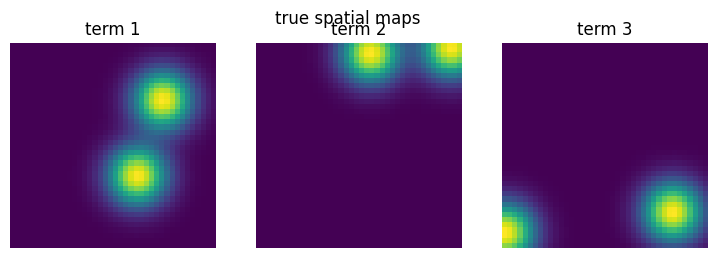

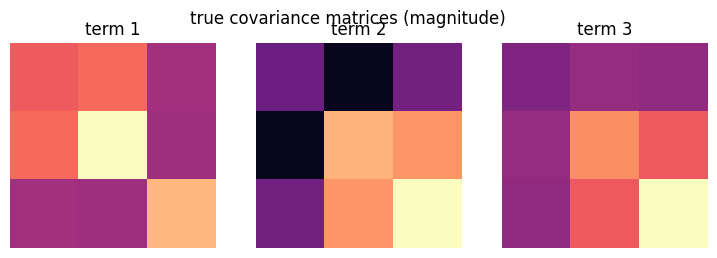

In [3]:
def show_maps(maps, title):
    """Plot one image per term, scaled so its strongest pixel is +1."""
    fig, axes = plt.subplots(1, len(maps), figsize=(3 * len(maps), 2.8))
    for r, (ax, m) in enumerate(zip(axes, maps, strict=True)):
        ax.imshow(m / m.flat[np.abs(m).argmax()], cmap="viridis")
        ax.set_title(f"term {r + 1}")
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


def show_covariances(C, title):
    """Plot the magnitude of each term's covariance matrix."""
    fig, axes = plt.subplots(1, C.shape[1], figsize=(3 * C.shape[1], 2.8))
    for r, ax in enumerate(axes):
        Sigma = C[:, r].reshape(K, K)
        ax.imshow(np.abs(Sigma) / np.abs(Sigma).max(), cmap="magma", vmin=0, vmax=1)
        ax.set_title(f"term {r + 1}")
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


show_maps(spatial_maps(A0, B0, L1), "true spatial maps")
show_covariances(C0, "true covariance matrices (magnitude)")

## Fit the model

The AO-ADMM solver keeps the spatial maps non-negative and every covariance matrix
positive semidefinite. A K-means initialization groups pixels with similar covariance
matrices to get a starting point.

  model.fit(T, init="kmeans", max_iter=2000, max_admm=50, rel_tol=1e-10, abs_tol=0)


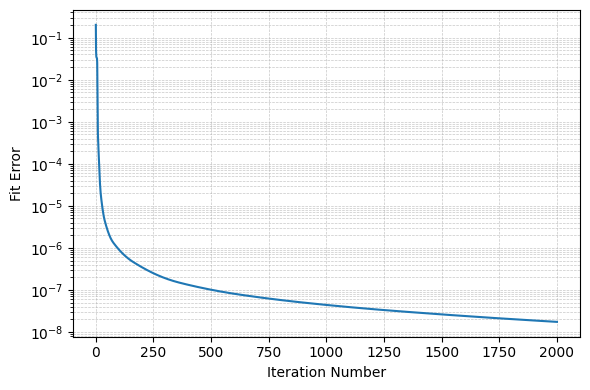

In [4]:
model.fit(T, init="kmeans", max_iter=2000, max_admm=50, rel_tol=1e-10, abs_tol=0)
plot_error(model.fit_error)

The solver stops at `max_iter` and warns, as the error is still slowly decreasing. The
estimate is already accurate, as the checks below show; a larger `max_iter` would refine
it further.

## Check the result

The recovered maps and covariance matrices match the true ones, up to the order of the
terms and a scaling shared between each map and its matrix:

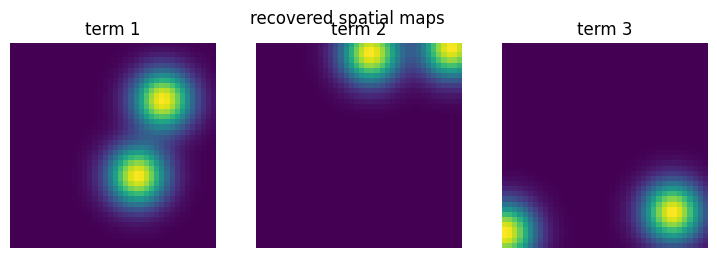

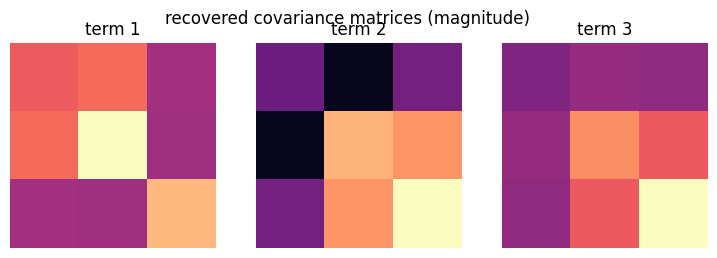

In [5]:
A, B, C = model.factors
show_maps(spatial_maps(A, B, L1), "recovered spatial maps")
show_covariances(C, "recovered covariance matrices (magnitude)")

The constraints hold and the relative error is small:

In [6]:
print("A, B non-negative:", A.min() >= 0, B.min() >= 0)
print(
    "valid covariances:", [is_valid_covariance(c.reshape(K, K), tol=1e-8) for c in C.T]
)
print("relative error:", np.linalg.norm(model.tensor - T) / np.linalg.norm(T))

A, B non-negative: True True
valid covariances: [True, True, True]
relative error: 0.0001316421358196799


Cov-LL1 does not constrain the rank L2 of the covariance matrices; the fourth-order
[BBTD model](bbtd-admm.ipynb) does.